# 4-qadam: Ma'lumotni tahlil qilish (EDA) va tozalash

**Maqsad:** sensor ma'lumotini tushunish, xatolarini topish va ML (5-qadam) uchun tayyor qilish.

1. Ma'lumot sifatini tekshirish
2. Sensor xatolarini topish va tuzatish
3. Sug'orish hodisalarini ma'lumotdan ajratib olish
4. Zonalarni solishtirish va quruyish (bug'lanish) tezligini tahlil qilish
5. Qurilma salomatligi (batareya)
6. Tozalangan ma'lumotni saqlash

**Tayyorgarlik.** Baza to'ldirilgan bo'lishi kerak. Natijani "to'g'ri javob" bilan solishtirish uchun simulyatorni CSV bilan birga ishga tushiring
(oldin `hydromind.db` ni o'chiring):

```
python scripts/simulator.py backfill --days 30 --csv data/sim.csv
```

CSV bo'lmasa, baholash qismlari avtomatik o'tkazib yuboriladi, qolgan tahlil bemalol ishlaydi.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import create_engine

# Loyiha ildizini topamiz (notebook qayerdan ochilganidan qat'i nazar ishlaydi)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend").exists())
DB_PATH = ROOT / "hydromind.db"
LABELS_CSV = ROOT / "data" / "sim.csv"   # faqat simulyatorda bor "to'g'ri javob"lar
OUT_DIR = ROOT / "data"

TZ_OFFSET_H = 5   # Toshkent: UTC+5
STEP_MIN = 15     # o'lchovlar oralig'i

FOREST, SAGE, TERRA = "#1B4332", "#5C8A66", "#C97B4A"
ZONE_COLORS = {"zone_1": TERRA, "zone_2": SAGE, "zone_3": FOREST}

plt.rcParams.update({
    "figure.figsize": (11, 4.2), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Loyiha:", ROOT)

Loyiha: /home/claude/hydromind-agro


## 1. Ma'lumotni yuklash va sifatini tekshirish

In [2]:
engine = create_engine(f"sqlite:///{DB_PATH}")
raw = pd.read_sql("SELECT * FROM readings ORDER BY zone_id, timestamp", engine, parse_dates=["timestamp"])
if raw.empty:
    raise SystemExit("Baza bo'sh. Avval simulyatorni ishga tushiring: python scripts/simulator.py backfill --days 30")

raw["timestamp"] = raw["timestamp"].astype("datetime64[ns]")
print(f"Jami {len(raw)} qator, {raw['zone_id'].nunique()} zona, {raw['device_id'].nunique()} qurilma")
print(f"Davr (UTC): {raw['timestamp'].min()}  ->  {raw['timestamp'].max()}")
raw.head()

Jami 8640 qator, 3 zona, 3 qurilma
Davr (UTC): 2026-09-09 18:30:00  ->  2026-10-09 18:15:00


,id,device_id,zone_id,timestamp,soil_moisture_pct,soil_temp_c,air_temp_c,air_humidity_pct,battery_v
0,1,esp32_zone1_node1,zone_1,2026-09-09 18:30:00,32.4,23.2,22.8,59.8,3.85
1,4,esp32_zone1_node1,zone_1,2026-09-09 18:45:00,32.4,22.8,22.9,58.9,3.85
2,7,esp32_zone1_node1,zone_1,2026-09-09 19:00:00,32.4,23.1,23.1,58.1,3.85
3,10,esp32_zone1_node1,zone_1,2026-09-09 19:15:00,32.9,22.7,22.3,61.8,3.85
4,13,esp32_zone1_node1,zone_1,2026-09-09 19:30:00,32.5,22.3,22.1,65.2,3.85


In [3]:
# Sifat tekshiruvi: dublikat, bo'shliq (yo'qolgan o'lchovlar), bo'sh qiymatlar
dups = raw.duplicated(["zone_id", "timestamp"]).sum()
print(f"Dublikat (bir zona, bir vaqt): {dups}")
if dups:
    print("  -> simulyatorni ikki marta ishga tushirgan bo'lishingiz mumkin. hydromind.db ni o'chirib, qayta yarating.")

gaps = raw.sort_values(["zone_id", "timestamp"]).groupby("zone_id")["timestamp"].diff().dropna()
print("\nQo'shni o'lchovlar orasidagi vaqt (har zona bo'yicha jami):")
print(gaps.value_counts().head(5).to_string())

print("\nBo'sh qiymatlar soni:")
print(raw.isna().sum().to_string())

raw.describe().round(2)

Dublikat (bir zona, bir vaqt): 0

Qo'shni o'lchovlar orasidagi vaqt (har zona bo'yicha jami):
timestamp
0 days 00:15:00    8637

Bo'sh qiymatlar soni:
id                   0
device_id            0
zone_id              0
timestamp            0
soil_moisture_pct    0
soil_temp_c          0
air_temp_c           0
air_humidity_pct     0
battery_v            0


,id,timestamp,soil_moisture_pct,soil_temp_c,air_temp_c,air_humidity_pct,battery_v
count,8640.00,8640,8640.00,8640.00,8640.00,8640.00,8640.00
mean,4320.50,2026-09-24 18:22:30,37.09,23.15,26.61,47.13,3.92
min,1.00,2026-09-09 18:30:00,0.00,15.60,14.60,16.00,3.77
25%,2160.75,2026-09-17 06:26:15,32.40,19.90,21.30,32.10,3.83
50%,4320.50,2026-09-24 18:22:30,37.00,23.20,26.60,47.10,3.87
75%,6480.25,2026-10-02 06:18:45,41.10,26.40,31.90,62.20,4.02
max,8640.00,2026-10-09 18:15:00,99.70,31.10,57.50,77.60,4.18
std,2494.30,NaN,6.86,3.75,6.07,15.90,0.11


## 2. Sensor xatolarini topish

Xom ma'lumotda ba'zi qiymatlar fizik jihatdan mumkin emas: tuproq namligi 15 daqiqada 0 ga tushib, keyingi o'lchovda qaytib keladi.
Bunday xatolarning belgisi: **bitta nuqta ikkala qo'shnisidan ham bir tomonga keskin farq qiladi** (tepalik yoki o'pirilish).

Nega oddiy "chegaradan oshdi" qoidasi yetmaydi? Chunki haqiqiy sug'orishda namlik ham tez ko'tariladi (har 15 daqiqada ~5 punkt).
Lekin sug'orishda qiymat **ketma-ket** o'sadi (oldingidan baland, keyingisidan past), xato esa **o'zidan oldin ham, keyin ham** boshqacha bo'ladi.
Shuning uchun qoidamiz: ikkala farq ham katta **va bir xil ishorali** bo'lishi kerak.

In [4]:
def spike_flags(s: pd.Series, thr: float) -> pd.Series:
    """Bitta nuqta ikkala qo'shnisidan ham thr dan ko'p va bir tomonga farq qilsa, True."""
    d_prev = s - s.shift(1)
    d_next = s - s.shift(-1)
    return (d_prev.abs() > thr) & (d_next.abs() > thr) & (np.sign(d_prev) == np.sign(d_next))


df = raw.sort_values(["zone_id", "timestamp"]).reset_index(drop=True)
g = df.groupby("zone_id")

df["moist_spike"] = g["soil_moisture_pct"].transform(lambda s: spike_flags(s, thr=10))  # namlik: 10 punkt
df["air_spike"] = g["air_temp_c"].transform(lambda s: spike_flags(s, thr=6))            # havo: 6 daraja
df["anomaly_detected"] = df["moist_spike"] | df["air_spike"]

print("Topilgan xato o'lchovlar (zona bo'yicha):")
print(df.groupby("zone_id")[["moist_spike", "air_spike", "anomaly_detected"]].sum().to_string())

Topilgan xato o'lchovlar (zona bo'yicha):
         moist_spike  air_spike  anomaly_detected
zone_id                                          
zone_1             6          3                 9
zone_2             3          5                 8
zone_3             6          2                 8


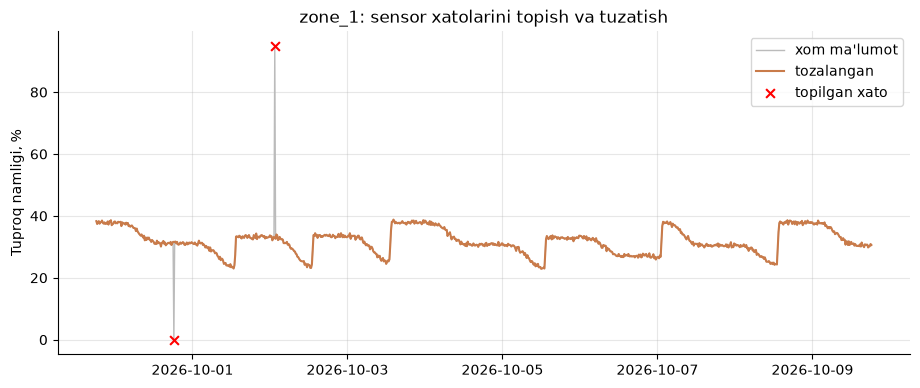

In [5]:
# Tozalash: xato qiymatni olib tashlab, qo'shni nuqtalar orasidan vaqt bo'yicha interpolyatsiya qilamiz
df["moisture"] = df["soil_moisture_pct"].where(~df["moist_spike"])
df["air_temp"] = df["air_temp_c"].where(~df["air_spike"])
for col in ["moisture", "air_temp"]:
    df[col] = df.groupby("zone_id")[col].transform(lambda s: s.interpolate(limit=3, limit_area="inside"))

# Vizual tekshiruv: eng ko'p xato topilgan zonaning so'nggi 10 kuni
zone = df.groupby("zone_id")["anomaly_detected"].sum().idxmax()
w = df[(df["zone_id"] == zone) & (df["timestamp"] >= df["timestamp"].max() - pd.Timedelta(days=10))]

fig, ax = plt.subplots()
ax.plot(w["timestamp"], w["soil_moisture_pct"], color="#bbbbbb", lw=1, label="xom ma'lumot")
ax.plot(w["timestamp"], w["moisture"], color=ZONE_COLORS[zone], lw=1.5, label="tozalangan")
bad = w[w["moist_spike"]]
ax.scatter(bad["timestamp"], bad["soil_moisture_pct"], color="red", marker="x", s=40, zorder=5, label="topilgan xato")
ax.set_title(f"{zone}: sensor xatolarini topish va tuzatish")
ax.set_ylabel("Tuproq namligi, %")
ax.legend(loc="upper right")
plt.show()

### Detektor qanchalik aniq? (to'g'ri javob bilan solishtirish)

Simulyator har bir xatoni o'zi qo'shgani uchun, qaysi qatorlar haqiqatan xato ekanini biladi. Real ma'lumotda bunday "javob varag'i" bo'lmaydi,
shuning uchun bu qism faqat detektor qoidamizni **sinash** uchun.

In [6]:
labels = None
if LABELS_CSV.exists():
    lab = pd.read_csv(LABELS_CSV)
    lab["timestamp"] = pd.to_datetime(lab["timestamp"], utc=True).dt.tz_localize(None).astype("datetime64[ns]")
    merged = df.merge(lab[["zone_id", "timestamp", "valve_open", "is_anomaly"]], on=["zone_id", "timestamp"], how="left")
    if merged["is_anomaly"].notna().mean() > 0.99:
        df = merged
        df["is_anomaly"] = df["is_anomaly"].astype(bool)
        df["valve_open"] = df["valve_open"].astype(bool)
        labels = True
    else:
        print("data/sim.csv bazadagi ma'lumotga mos kelmaydi (boshqa ishga tushirishdan qolgan). Baholash o'tkazib yuborildi.")
        print("Hal qilish: hydromind.db ni o'chirib, simulyatorni --csv bilan qayta ishga tushiring.")
else:
    print("data/sim.csv topilmadi. Baholash o'tkazib yuborildi.")

if labels:
    y, p = df["is_anomaly"], df["anomaly_detected"]
    tp, fp, fn = int((y & p).sum()), int((~y & p).sum()), int((y & ~p).sum())
    print(f"Haqiqiy xatolar: {int(y.sum())}")
    print(f"To'g'ri topilgan (TP): {tp},  noto'g'ri signal (FP): {fp},  o'tkazib yuborilgan (FN): {fn}")
    print(f"Aniqlik (precision): {tp / max(tp + fp, 1):.1%},  to'liqlik (recall): {tp / max(tp + fn, 1):.1%}")

Haqiqiy xatolar: 25
To'g'ri topilgan (TP): 25,  noto'g'ri signal (FP): 0,  o'tkazib yuborilgan (FN): 0
Aniqlik (precision): 100.0%,  to'liqlik (recall): 100.0%


## 3. Vaqt belgilari va zonalarni solishtirish

Kun va soat bo'yicha tahlil uchun vaqtni Toshkent vaqtiga o'tkazamiz (bazada UTC saqlanadi).

In [7]:
df["local_time"] = df["timestamp"] + pd.Timedelta(hours=TZ_OFFSET_H)
df["hour_local"] = df["local_time"].dt.hour
df["date_local"] = df["local_time"].dt.date

STRESS_BELOW = 25  # shartli "quruq" chegarasi (namuna uchun; haqiqiy qiymat ekin va tuproqqa bog'liq)
summary = df.groupby("zone_id").agg(
    o_rtacha_namlik=("moisture", "mean"),
    min_namlik=("moisture", "min"),
    max_namlik=("moisture", "max"),
    quruq_vaqt_ulushi=("moisture", lambda s: (s < STRESS_BELOW).mean()),
).round(2)
summary["quruq_vaqt_ulushi"] = (summary["quruq_vaqt_ulushi"] * 100).round(1)
summary.rename(columns={"quruq_vaqt_ulushi": f"namlik<{STRESS_BELOW}% vaqt, %"})

,o_rtacha_namlik,min_namlik,max_namlik,"namlik<25% vaqt, %"
zone_id,,,,
zone_1,31.97,20.3,38.9,7.0
zone_2,36.42,25.4,45.8,0.0
zone_3,42.77,31.5,53.0,0.0


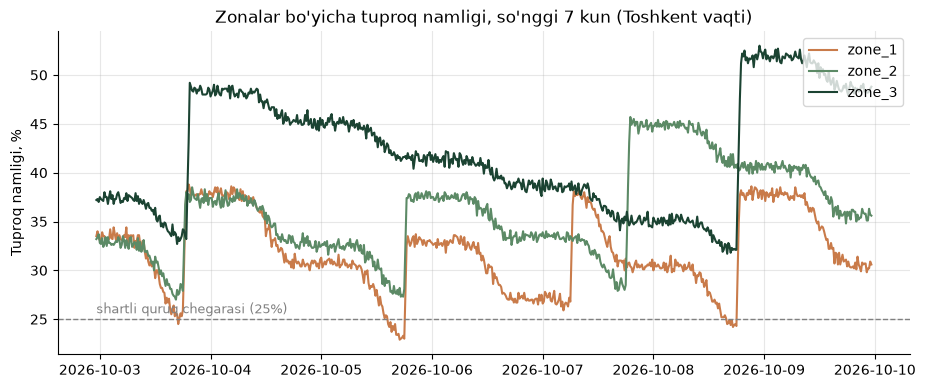

In [8]:
last7 = df[df["timestamp"] >= df["timestamp"].max() - pd.Timedelta(days=7)]
fig, ax = plt.subplots()
for z, gz in last7.groupby("zone_id"):
    ax.plot(gz["local_time"], gz["moisture"], color=ZONE_COLORS[z], label=z, lw=1.5)
ax.axhline(STRESS_BELOW, color="gray", ls="--", lw=1)
ax.text(last7["local_time"].min(), STRESS_BELOW + 0.6, f"shartli quruq chegarasi ({STRESS_BELOW}%)", color="gray", fontsize=9)
ax.set_title("Zonalar bo'yicha tuproq namligi, so'nggi 7 kun (Toshkent vaqti)")
ax.set_ylabel("Tuproq namligi, %")
ax.legend(loc="upper right")
plt.show()

## 4. Sug'orish hodisalarini ajratib olish

Bazada klapan holati yo'q (haqiqiy tizimda ham dastlab bo'lmasligi mumkin), lekin sug'orishni **namlikning keskin ko'tarilishidan** bilib olamiz:
15 daqiqada 2,5 punktdan ko'p o'sish (sensor shovqini va oddiy bug'lanish bunday o'sish bermaydi).
Ketma-ket shunday qadamlar bitta sug'orish hodisasini tashkil etadi.

Bitta shovqinli sakrashni sug'orish deb adashmaslik uchun yana bir shart: namlik hodisadan **keyingi o'lchovda ham baland qolishi** kerak.
Haqiqiy sug'orishdan keyin tuproq nam bo'lib qoladi, sensor shovqini esa darrov qaytib tushadi.

In [9]:
RISE_THRESHOLD = 2.5  # 15 daqiqada namlik o'sishi (punkt)

df["dm"] = df.groupby("zone_id")["moisture"].diff()
df["irr_step"] = df["dm"] >= RISE_THRESHOLD


def find_events(gz: pd.DataFrame) -> list[dict]:
    gz = gz.reset_index(drop=True)
    run_id = (gz["irr_step"] != gz["irr_step"].shift()).cumsum()
    out = []
    for _, idx in gz[gz["irr_step"]].groupby(run_id[gz["irr_step"]]).groups.items():
        i0, i1 = idx[0], idx[-1]
        before = gz.loc[i0 - 1, "moisture"] if i0 > 0 else np.nan
        next_val = gz.loc[min(i1 + 1, len(gz) - 1), "moisture"]
        if not (next_val - before >= RISE_THRESHOLD):   # baland qolmasa, bu shovqin
            continue
        out.append({
            "zone_id": gz.loc[0, "zone_id"],
            "start": gz.loc[i0, "timestamp"],
            "minutes": (i1 - i0 + 1) * STEP_MIN,
            "moisture_before": before,
            "moisture_after": gz.loc[i1, "moisture"],
        })
    return out


events = pd.DataFrame([e for _, gz in df.groupby("zone_id") for e in find_events(gz)])
events["rise"] = events["moisture_after"] - events["moisture_before"]
events["start_local"] = events["start"] + pd.Timedelta(hours=TZ_OFFSET_H)
events["start_hour"] = events["start_local"].dt.hour
events = events.sort_values(["zone_id", "start"]).reset_index(drop=True)
events["hours_since_prev"] = events.groupby("zone_id")["start"].diff().dt.total_seconds() / 3600

ev_summary = events.groupby("zone_id").agg(
    sugorishlar_soni=("start", "count"),
    ortacha_oraliq_soat=("hours_since_prev", "mean"),
    ortacha_davomiylik_daqiqa=("minutes", "mean"),
    ortacha_osish_punkt=("rise", "mean"),
).round(1)
ev_summary

,sugorishlar_soni,ortacha_oraliq_soat,ortacha_davomiylik_daqiqa,ortacha_osish_punkt
zone_id,,,,
zone_1,20,35.4,36.8,11.8
zone_2,12,56.7,41.2,13.5
zone_3,7,104.0,51.4,16.8


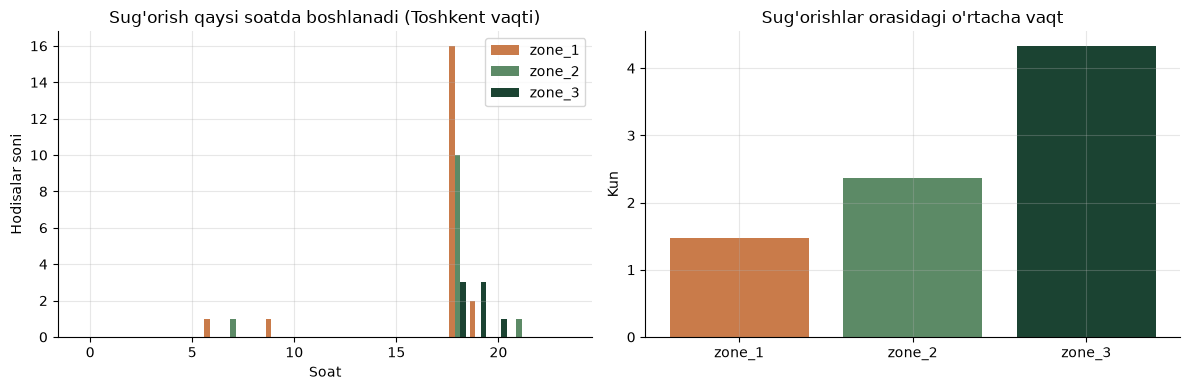

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

hours = np.arange(24)
width = 0.27
for k, (z, ge) in enumerate(events.groupby("zone_id")):
    counts = ge["start_hour"].value_counts().reindex(hours, fill_value=0)
    axes[0].bar(hours + (k - 1) * width, counts.values, width, color=ZONE_COLORS[z], label=z)
axes[0].set_title("Sug'orish qaysi soatda boshlanadi (Toshkent vaqti)")
axes[0].set_xlabel("Soat")
axes[0].set_ylabel("Hodisalar soni")
axes[0].legend()

iv = events.groupby("zone_id")["hours_since_prev"].mean() / 24
axes[1].bar(iv.index, iv.values, color=[ZONE_COLORS[z] for z in iv.index])
axes[1].set_title("Sug'orishlar orasidagi o'rtacha vaqt")
axes[1].set_ylabel("Kun")
plt.tight_layout()
plt.show()

### Sug'orish hodisalari to'g'ri topildimi?

In [11]:
if labels:
    def true_starts(gz):
        v = gz["valve_open"].reset_index(drop=True)
        return gz["timestamp"].reset_index(drop=True)[v & ~v.shift(fill_value=False)]

    true_ev = pd.concat(
        [pd.DataFrame({"zone_id": z, "t": true_starts(gz)}) for z, gz in df.groupby("zone_id")], ignore_index=True
    ).astype({"t": "datetime64[ns]"})
    det_ev = events[["zone_id", "start"]].rename(columns={"start": "t"}).astype({"t": "datetime64[ns]"})

    def hit_rate(a, b, tol="30min"):
        a, b = a.sort_values("t"), b.sort_values("t").assign(hit=True)
        m = pd.merge_asof(a, b, on="t", by="zone_id", tolerance=pd.Timedelta(tol), direction="nearest")
        return m["hit"].notna().mean()

    print(f"Haqiqiy sug'orishlar: {len(true_ev)},  biz topganlar: {len(det_ev)}")
    print(f"Aniqlik (topganlarimizning haqiqiylari): {hit_rate(det_ev, true_ev):.1%}")
    print(f"To'liqlik (haqiqiylarning topilganlari): {hit_rate(true_ev, det_ev):.1%}")
else:
    print("To'g'ri javob (data/sim.csv) yo'q, baholash o'tkazib yuborildi.")

Haqiqiy sug'orishlar: 39,  biz topganlar: 39
Aniqlik (topganlarimizning haqiqiylari): 100.0%
To'liqlik (haqiqiylarning topilganlari): 100.0%


## 5. Quruyish tezligi: tuproq nimaga qarab tez quriydi?

Bu ML modelning eng muhim "xom ashyosi": agar quruyish tezligini harorat, namlik va soatga bog'lay olsak, namlik chegaradan qachon pastga tushishini oldindan aytish mumkin.

Quruyish tezligini **1 soatlik farq** bilan o'lchaymiz (hozirgi namlik minus 1 soatdan keyingisi, %/soat). Oraliqda sug'orish bo'lgan davrlarni chiqarib tashlaymiz.

Tahlil uchun yaroqli kuzatuvlar: 8318 / 8640


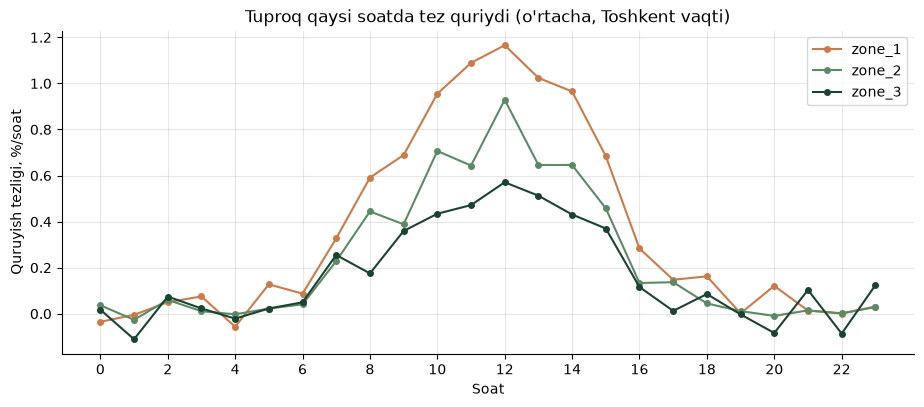

In [12]:
# Keyingi 1 soatda (4 qadam) sug'orish bo'lgan davrlarni belgilaymiz
irr_ahead = df.groupby("zone_id")["irr_step"].transform(
    lambda s: s.astype(float).rolling(6, min_periods=1).max().shift(-5)
).fillna(1.0).astype(bool)

df["drying_1h"] = df["moisture"] - df.groupby("zone_id")["moisture"].shift(-4)   # %/soat, musbat = quriyapti
valid = df[~irr_ahead & df["drying_1h"].notna()].copy()
print(f"Tahlil uchun yaroqli kuzatuvlar: {len(valid)} / {len(df)}")

hourly = valid.groupby(["hour_local", "zone_id"])["drying_1h"].mean().unstack()
fig, ax = plt.subplots()
for z in hourly.columns:
    ax.plot(hourly.index, hourly[z], color=ZONE_COLORS[z], marker="o", ms=4, label=z)
ax.set_title("Tuproq qaysi soatda tez quriydi (o'rtacha, Toshkent vaqti)")
ax.set_xlabel("Soat")
ax.set_ylabel("Quruyish tezligi, %/soat")
ax.set_xticks(range(0, 24, 2))
ax.legend()
plt.show()

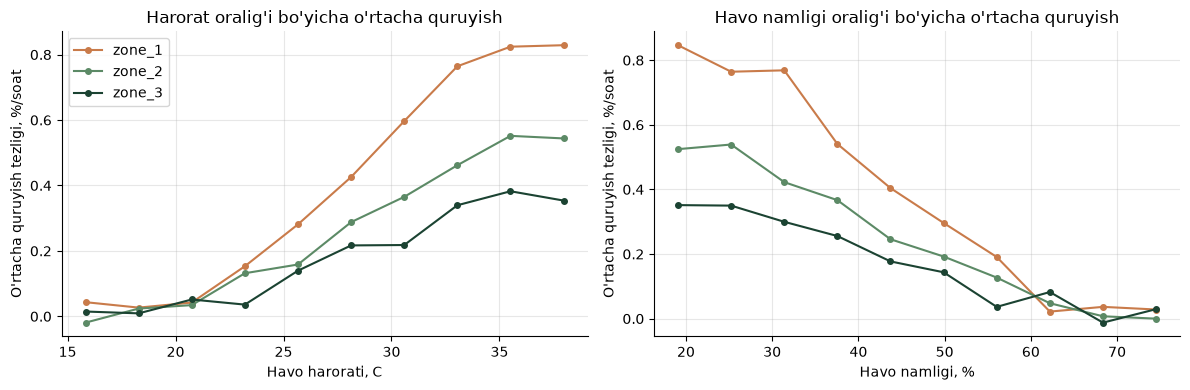

Quruyish tezligi bilan korrelyatsiya:


,zone_1,zone_2,zone_3
air_temp,0.43,0.30,0.22
air_humidity_pct,-0.43,-0.30,-0.21
soil_temp_c,0.20,0.13,0.09


In [13]:
# Nuqtalar juda ko'p va bir-birini bosadi, shuning uchun oraliqlar bo'yicha o'rtacha qiymatni chizamiz
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, xlabel in [(axes[0], "air_temp", "Havo harorati, C"), (axes[1], "air_humidity_pct", "Havo namligi, %")]:
    edges = np.linspace(valid[col].min(), valid[col].max(), 11)
    mids = (edges[:-1] + edges[1:]) / 2
    for z, gz in valid.groupby("zone_id"):
        binned = gz.groupby(pd.cut(gz[col], bins=edges), observed=False)["drying_1h"].mean()
        ax.plot(mids, binned.values, color=ZONE_COLORS[z], marker="o", ms=4, label=z)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("O'rtacha quruyish tezligi, %/soat")
axes[0].set_title("Harorat oralig'i bo'yicha o'rtacha quruyish")
axes[1].set_title("Havo namligi oralig'i bo'yicha o'rtacha quruyish")
axes[0].legend()
plt.tight_layout()
plt.show()

cols = ["air_temp", "air_humidity_pct", "soil_temp_c"]
corr = pd.DataFrame({z: valid[valid["zone_id"] == z][cols + ["drying_1h"]].corr()["drying_1h"].drop("drying_1h")
                     for z in sorted(valid["zone_id"].unique())}).round(2)
print("Quruyish tezligi bilan korrelyatsiya:")
corr

**Qanday o'qiladi.** Quruyish tezligi kunduzi (issiq, quyoshli soatlarda) eng baland, kechasi nolga yaqin. Harorat bilan musbat, havo namligi bilan manfiy bog'liq.
Simulyator ma'lumotida zonalar farqi kutilganidek tuproq turidan: qumloq zona (zone_1) eng tez, gil zona (zone_3) eng sekin quriydi.
Haqiqiy dalada ham shu farqni topish aynan shu tahlilning vazifasi.

Diqqat: harorat, havo namligi va soat o'zaro bog'liq (kun davomida birga o'zgaradi), shuning uchun alohida korrelyatsiya qiymatlarini "sabab" deb o'qimang.
ML bosqichida ularni birga hisobga olamiz.

## 6. Qurilma salomatligi (batareya)

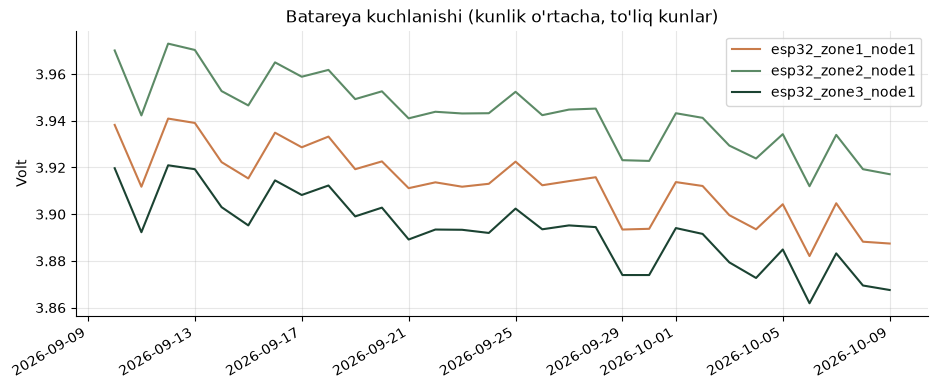

,min_v,ortacha_v,kunlik_ozgarish_v
device_id,,,
esp32_zone1_node1,3.79,3.91,-0.0015
esp32_zone2_node1,3.82,3.94,-0.0015
esp32_zone3_node1,3.77,3.89,-0.0015


In [14]:
# Faqat to'liq kunlar olinadi: kunning bir qismi bo'lgan chekka kunlar (masalan, faqat tungi soatlar) o'rtachani buzadi
counts = df.groupby(["date_local", "device_id"])["battery_v"].count().unstack()
full_days = counts.index[(counts >= 90).all(axis=1)]    # 96 ta o'lchovning kamida 90 tasi
battery_daily = df.groupby(["date_local", "device_id"])["battery_v"].mean().unstack().loc[full_days]

fig, ax = plt.subplots()
for dev in battery_daily.columns:
    z = dev.split("_")[1].replace("zone", "zone_")
    ax.plot(pd.to_datetime(battery_daily.index), battery_daily[dev], color=ZONE_COLORS.get(z, "gray"), label=dev)
ax.set_title("Batareya kuchlanishi (kunlik o'rtacha, to'liq kunlar)")
ax.set_ylabel("Volt")
ax.legend()
fig.autofmt_xdate()
plt.show()

health = df.groupby("device_id")["battery_v"].agg(min_v="min", ortacha_v="mean").round(2)
slope = {d: np.polyfit(np.arange(len(battery_daily)), battery_daily[d].values, 1)[0] for d in battery_daily.columns}
health["kunlik_ozgarish_v"] = pd.Series(slope).round(4)
health

## 7. Xulosa va tozalangan ma'lumotni saqlash

Quyidagi xulosa to'g'ridan-to'g'ri sizning ma'lumotingizdan hisoblanadi.

In [15]:
daily_dry = valid.groupby("zone_id")["drying_1h"].mean() * 24   # taxminiy, %/kun (sug'orishsiz davrlar uchun)
peak_hour = valid.groupby("hour_local")["drying_1h"].mean().idxmax()
# Namlik klapan ochilgandan 15 daqiqa keyin ko'tariladi, shuning uchun 9:xx va 21:xx ham oynaga kiradi
in_window = events["start_hour"].between(5, 9) | events["start_hour"].between(18, 21)

print("XULOSA")
print("-" * 60)
print(f"- Davr: {df['local_time'].min():%Y-%m-%d} dan {df['local_time'].max():%Y-%m-%d} gacha, {df['zone_id'].nunique()} zona")
print(f"- Sensor xatolari: {int(df['anomaly_detected'].sum())} ta ({df['anomaly_detected'].mean():.2%}), tuzatildi")
fast, slow = daily_dry.idxmax(), daily_dry.idxmin()
print(f"- Eng tez quriydigan zona: {fast} (~{daily_dry[fast]:.1f} %/kun), eng sekin: {slow} (~{daily_dry[slow]:.1f} %/kun)")
print(f"- Tuproq eng tez quriydigan soat: {peak_hour}:00 (Toshkent vaqti)")
print(f"- Jami {len(events)} ta sug'orish; ularning {in_window.mean():.0%} i ertalab (5-9) yoki kechqurun (18-21) boshlangan")
for z, r in ev_summary.iterrows():
    print(f"  {z}: har ~{r['ortacha_oraliq_soat'] / 24:.1f} kunda, o'rtacha {r['ortacha_davomiylik_daqiqa']:.0f} daqiqa, namlik +{r['ortacha_osish_punkt']:.0f} punkt")

XULOSA


------------------------------------------------------------
- Davr: 2026-09-09 dan 2026-10-09 gacha, 3 zona
- Sensor xatolari: 25 ta (0.29%), tuzatildi
- Eng tez quriydigan zona: zone_1 (~8.8 %/kun), eng sekin: zone_3 (~4.0 %/kun)
- Tuproq eng tez quriydigan soat: 12:00 (Toshkent vaqti)
- Jami 39 ta sug'orish; ularning 100% i ertalab (5-9) yoki kechqurun (18-21) boshlangan
  zone_1: har ~1.5 kunda, o'rtacha 37 daqiqa, namlik +12 punkt
  zone_2: har ~2.4 kunda, o'rtacha 41 daqiqa, namlik +14 punkt
  zone_3: har ~4.3 kunda, o'rtacha 51 daqiqa, namlik +17 punkt


In [16]:
# 5-qadam (ML) uchun saqlaymiz
clean_cols = ["timestamp", "local_time", "zone_id", "device_id", "moisture", "soil_temp_c", "air_temp",
              "air_humidity_pct", "battery_v", "anomaly_detected", "irr_step", "drying_1h"]
OUT_DIR.mkdir(exist_ok=True)
df[clean_cols].to_csv(OUT_DIR / "clean_readings.csv", index=False)
events.to_csv(OUT_DIR / "irrigation_events.csv", index=False)
print(f"Saqlandi: {OUT_DIR / 'clean_readings.csv'}  ({len(df)} qator)")
print(f"Saqlandi: {OUT_DIR / 'irrigation_events.csv'}  ({len(events)} hodisa)")

Saqlandi: /home/claude/hydromind-agro/data/clean_readings.csv  (8640 qator)
Saqlandi: /home/claude/hydromind-agro/data/irrigation_events.csv  (39 hodisa)
